In [2]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.15.0+cu132
TorchVision: 0.29.2+cu132
CUDA runtime: 13.2
CUDA available: True
GPU: NVIDIA GeForce MX550


## Imports

In [3]:
from pathlib import Path
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import vgg16, VGG16_Weights

## Experiment Configuration

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# prefer reproducible behavior over small performance difference
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
# cuDNN can choose among several implementations of the same GPU operation.
# These settings favor repeatability instead of allowing it to select
# potentially different implementations between runs

CLASS_NAMES = [
    "angry",
    "happy",
    "sad",
]

# class mapping:
# angry -> 0, happy -> 1, sad -> 2
CLASS_TO_LABEL = {
    class_name: label
    for label, class_name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)

# training config
BATCH_SIZE = 16 # small so i dont torch my laptop lol
NUM_WORKERS = 0 # apparently done to avoid windows nonsense in jupyter

# select the best available device without requiring code changes
if torch.cuda.is_available():
    device = torch.device("cuda")
elif (
    hasattr(torch.backends, "mps")
    and torch.backends.mps.is_available()
):
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Classes:", CLASS_NAMES)
print("CLass mapping:", CLASS_TO_LABEL)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Selected device:", device)

Classes: ['angry', 'happy', 'sad']
CLass mapping: {'angry': 0, 'happy': 1, 'sad': 2}
Number of classes: 3
Batch size: 16
Selected device: cuda


## Discover Available Datasets

In [7]:
import sys
from pathlib import Path


# Search the current directory and each parent directory
# until we find the repository root.
search_locations = [
    Path.cwd(),
    *Path.cwd().parents,
]

PROJECT_ROOT = next(
    (
        location
        for location in search_locations
        if (
            location
            / "capstone_data"
            / "__init__.py"
        ).is_file()
    ),
    None,
)


# Stop with a clear error if the repository cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the Capstone-DATA4381 repository root."
    )


# Add the repository root to Python's module search path.
project_root_string = str(PROJECT_ROOT)

if project_root_string not in sys.path:
    sys.path.insert(
        0,
        project_root_string,
    )


# The import now works because Python can see the repository root.
import capstone_data.image_loader as loader


available_datasets = loader.list_datasets()

print("Project root:", PROJECT_ROOT)
print("\nAvailable datasets:")

for dataset_name, dataset_path in available_datasets.items():
    print(
        f"  {dataset_name}: {dataset_path}"
    )

Project root: C:\Users\mashe\code\class\Capstone-DATA4381

Available datasets:
  final: C:\Users\mashe\code\class\Capstone-DATA4381\data\final
  aug_data_v1: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v1
  aug_data_v3: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3


## Load Training, Validation, and Test Records

In [9]:
# Confirm that the notebook and loader use identical labels.
assert (
    loader.CLASS_TO_INDEX
    == CLASS_TO_LABEL
), "Notebook and image loader label mappings do not match."


# Load the three existing Augmented V1 partitions.
dataset_splits = {}

for split_name in (
    "train",
    "validation",
    "test",
):
    dataset_splits[split_name] = loader.load_dataset(
        "aug_data_v1",
        split=split_name,
    )


# Give each partition a convenient individual name.
train_records = dataset_splits["train"]
validation_records = dataset_splits["validation"]
test_records = dataset_splits["test"]


# Display the size and class distribution of every partition.
for split_name, records in dataset_splits.items():
    class_counts = loader.count_images_by_class(
        records
    )

    print(f"\n{split_name.title()}:")
    print(f"  Total images: {len(records)}")
    print(
        f"  Class counts: {dict(class_counts)}"
    )


Train:
  Total images: 14019
  Class counts: {'angry': 4673, 'happy': 4673, 'sad': 4673}

Validation:
  Total images: 1662
  Class counts: {'angry': 479, 'happy': 1002, 'sad': 181}

Test:
  Total images: 1673
  Class counts: {'angry': 463, 'happy': 1029, 'sad': 181}


## Configure VGG16 Image Preprocessing

In [12]:
# select the standard pretrained VGG16 weights
VGG16_WEIGHTS = VGG16_Weights.DEFAULT
 # in this case the pretrained weights come from ImageNet

# obtain the preprocessing pipeline associated with those weights
vgg_transform = VGG16_WEIGHTS.transforms()
# we need to transform our images to how the images that were fed
# into VGG16's original model was (ImageNet's preprocessing of their 
# images)

print("Selected weights:")
print(VGG16_WEIGHTS)

print("\nVGG16 preprocessing:")
print(vgg_transform)

Selected weights:
VGG16_Weights.IMAGENET1K_V1

VGG16 preprocessing:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


## Define the PyTorch Dataset

In [13]:
class FERDataset(Dataset):
    """
    Load FER images lazily from image-loader records

    Each requested sample returns:
        image: transformed PyTorch tensor
        label: integer PyTorch tensor
    """

    def __init__(
        self,
        records,
        transform=None,
    ):
        self.records = list(records)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(
        self,
        index,
    ):
        record = self.records[index]

        image_path = record["path"]
        label = record["label"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform is not None:
                image = self.transform(image)

        label = torch.tensor(
            label,
            dtype=torch.long,
        )

        return image, label

## Create and Inspect the PyTorch Datasets

In [14]:
train_dataset = FERDataset(
    records=train_records,
    transform=vgg_transform,
)

validation_dataset = FERDataset(
    records=validation_records,
    transform=vgg_transform,
)

test_dataset = FERDataset(
    records=test_records,
    transform=vgg_transform,
)


print("Dataset sizes:")
print(f"  Train:      {len(train_dataset)}")
print(f"  Validation: {len(validation_dataset)}")
print(f"  Test:       {len(test_dataset)}")


# Request one transformed sample from the training dataset.
sample_image, sample_label = train_dataset[0]
sample_record = train_records[0]


print("\nFirst training sample:")
print(f"  Path: {sample_record['path']}")
print(f"  Stored class name: {sample_record['class_name']}")
print(f"  Numeric label: {sample_label.item()}")
print(f"  Label class name: {CLASS_NAMES[sample_label.item()]}")
print(f"  Image shape: {tuple(sample_image.shape)}")
print(f"  Image data type: {sample_image.dtype}")
print(f"  Label data type: {sample_label.dtype}")
print(f"  Minimum value: {sample_image.min().item():.4f}")
print(f"  Maximum value: {sample_image.max().item():.4f}")

Dataset sizes:
  Train:      14019
  Validation: 1662
  Test:       1673

First training sample:
  Path: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v1\angry\train\augmented_000000.jpg
  Stored class name: angry
  Numeric label: 0
  Label class name: angry
  Image shape: (3, 224, 224)
  Image data type: torch.float32
  Label data type: torch.int64
  Minimum value: -2.1179
  Maximum value: 2.5180


## Inspect transformed image

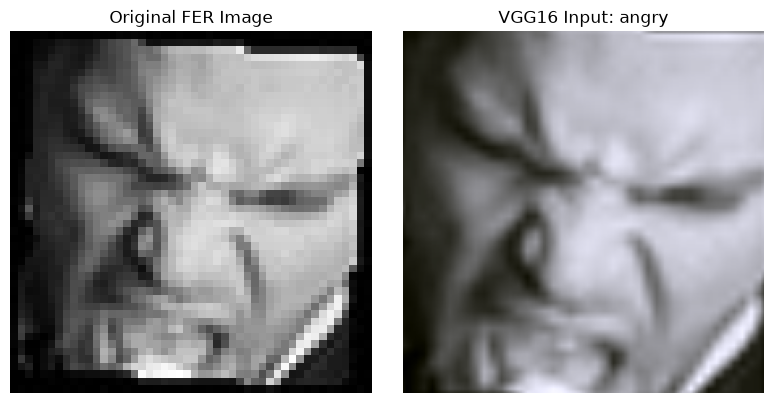

In [15]:
# ImageNet normalization values used by VGG16
image_mean = torch.tensor(
    [0.485, 0.456, 0.406],
).view(3,1,1)

image_std = torch.tensor(
    [0.229, 0.224, 0.255],
).view(3, 1, 1)

# work on a copy so the dataset tensor isnt changed
display_tensor = sample_image.clone()

# Rerverse the normalization:
# noramlized = (original - mean) / std
# original = normalized * std + mean
display_tensor = (
    display_tensor
    * image_std
    + image_mean
)

# protect against tiny numerical values outside [0, 1]
display_tensor = display_tensor.clamp(
    0.0,
    1.0,
)

# change PyTorch's (C, H, W) format into
# Matplotlib's (H, W, C) format
display_array = (
    display_tensor
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)

# open a separate copy of the original image
with Image.open(sample_record["path"]) as image:
    original_image = image.convert("L").copy()

figure, axes = plt.subplots(
    1,
    2,
    figsize=(8,4),
)

axes[0].imshow(
    original_image,
    cmap="gray",
)
axes[0].set_title("Original FER Image")
axes[0].axis("off")

axes[1].imshow(display_array)
axes[1].set_title(
    f"VGG16 Input: {sample_record['class_name']}"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()


## Create the DataLoaders

In [16]:
# Use pinned memory only when transferring batches to CUDA
use_pinned_memory = (
    device.type == "cuda"
)

# Give training shuffling its own reproducible random generator
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=use_pinned_memory,
    generator=loader_generator,
)

validation_loader = DataLoader(
    dataset=validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_pinned_memory,
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=use_pinned_memory,
)

print("Number of batches:")
print(f"  Train:      {len(train_loader)}")
print(f"  Validation: {len(validation_loader)}")
print(f"  Test:       {len(test_loader)}")

# retrieve one complete training batch
batch_images, batch_labels = next(
    iter(train_loader)
)

print("\nFirst training batch:")
print(f"  Image batch shape: {tuple(batch_images.shape)}")
print(f"  Label batch shape: {tuple(batch_labels.shape)}")
print(f"  Image data type:   {batch_images.dtype}")
print(f"  Label data type:   {batch_labels.dtype}")
print(f"  Label:             {batch_labels.tolist()}")

Number of batches:
  Train:      877
  Validation: 104
  Test:       105

First training batch:
  Image batch shape: (16, 3, 224, 224)
  Label batch shape: (16,)
  Image data type:   torch.float32
  Label data type:   torch.int64
  Label:             [0, 1, 0, 0, 2, 2, 1, 2, 2, 2, 1, 1, 1, 1, 0, 1]


## Build the VGG16 Transfer-Learning Model

In [17]:
# Load VGG16 with pretrained ImageNet parameters
model = vgg16(
    weights=VGG16_WEIGHTS,
)

# freeze the pretrained convolutional feature extractor
for parameter in model.features.parameters():
    parameter.requires_grad = False

# replace VGG16's original ImageNet classifier
# with a smaller classifier for our three emotions
model.classifier = nn.Sequential(
    nn.Linear(
        512 * 7 * 7,
        256,
    ),
    nn.ReLU(),
    nn.Dropout(
        p=0.5,
    ),
    nn.Linear(
        256,
        NUM_CLASSES,
    ),
)

# move the complete model to the selected device
model = model.to(device)

# count all parameters and those that will be updated
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Model device:", next(model.parameters()).device)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")

print("\nCustom classifier:")
print(model.classifier)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\mashe/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:51<00:00, 4.98MB/s] 


Model device: cuda:0
Total parameters: 21,138,243
Trainable parameters: 6,423,555

Custom classifier:
Sequential(
  (0): Linear(in_features=25088, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=256, out_features=3, bias=True)
)


## Test a Forward Pass

In [19]:
# put the model into eval mode
model.eval()

# reset CUDA's peak-memory measurement before this test
if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats(
        device
    )

# disable gradient tracking because this is only a test
with torch.inference_mode():
    device_images = batch_images.to(
        device,
        non_blocking=use_pinned_memory,
    )

    logits = model(
        device_images
    )

    predicted_labels = logits.argmax(
        dim=1
    )

predicted_class_names = [
    CLASS_NAMES[label]
    for label in predicted_labels.cpu().tolist()
]

print("Forward pass completed.")
print(f"  Input shape: {tuple(device_images.shape)}")
print(f"  Input device: {device_images.device}")
print(f"  Output shape: {tuple(logits.shape)}")
print(f"  Output device: {logits.device}")

print(
    "\nActual labels:",
    batch_labels.tolist(),
)

print(
    "Predicted labels:",
    predicted_labels.cpu().tolist(),
)

print(
    "Predicted classes:",
    predicted_class_names,
)

if device.type == "cuda":
    peak_memory_mb = (
        torch.cuda.max_memory_allocated(device)
        / 1024**2
    )

    print(
        f"\nPeak CUDA memory: "
        f"{peak_memory_mb:.2f} MB"
    )

Forward pass completed.
  Input shape: (16, 3, 224, 224)
  Input device: cuda:0
  Output shape: (16, 3)
  Output device: cuda:0

Actual labels: [0, 1, 0, 0, 2, 2, 1, 2, 2, 2, 1, 1, 1, 1, 0, 1]
Predicted labels: [2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 0, 2, 2, 1, 2]
Predicted classes: ['sad', 'sad', 'sad', 'sad', 'happy', 'sad', 'happy', 'sad', 'sad', 'sad', 'sad', 'angry', 'sad', 'sad', 'happy', 'sad']

Peak CUDA memory: 1365.26 MB


#### batch images -> frozen VGG16 features -> adaptive pooling -> flatten to 25,088 features -> custom classifier -> three logits per image

## Loss Function and Optimizer

In [20]:
# loss funciton
# CrossEntropyLoss compares the three output logits against the correct label
# class. OUr training set is balanced, so class weights are not needed here.
criterion = nn.CrossEntropyLoss()

# optimize only parameters that are allowed to train
# The frozen VGG16 feature extractor is automatically excluded
trainable_parameters = [
    parameter
    for parameter in model.parameters()
    if parameter.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=1e-4,
    weight_decay=1e-4,
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", optimizer.param_groups[0]["weight_decay"])
print(
    "Parameters given to optimizer:",
    sum(parameter.numel() for parameter in trainable_parameters),
)



Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Weight decay: 0.0001
Parameters given to optimizer: 6423555


## Training-style Forward and Backward Pass (No Model Update)

In [22]:
# remove GPU tensors left over form the inference test
for variable_name in (
    "device_images",
    "logits",
    "predicted_labels",
):
    globals().pop(variable_name, None)

if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

# training mode enables dropout in our custom classifier
model.train()

# remove any existing gradients
optimizer.zero_grad(set_to_none=True)

# transfer one batch to the selected device
train_images = batch_images.to(
    device,
    non_blocking=use_pinned_memory,
)

train_labels = batch_labels.to(
    device,
    non_blocking=use_pinned_memory,
)

# forward pass
train_logits = model(train_images)

# compare predictions against the correct labels
train_loss = criterion(
    train_logits,
    train_labels,
)

# calculate gradients for all trainable parameters
train_loss.backward()

# verify that the classifier received gradients
classifier_has_gradients = (
    model.classifier[0].weight.grad is not None
)

# verify that the frozen  feature extractor received no gradients
feature_gradients = sum(
    parameter.grad is not None
    for parameter in model.features.parameters()
)

if device.type == "cuda":
    torch.cuda.synchronize()

print("Backward pass completed.")
print(f"Loss: {train_loss.item():.4f}")
print("Logit shape:", tuple(train_logits.shape))
print("Classifier has gradients:", classifier_has_gradients)
print("Feature gradients:", feature_gradients)

if device.type == "cuda":
    peak_memory_mb = (
        torch.cuda.max_memory_allocated(device)
        / 1024**2
    )
    print(f"Peak CUDA memory: {peak_memory_mb:.2f} MB")

# discard the test gradients without changing the model
optimizer.zero_grad(set_to_none=True)

del train_images
del train_labels
del train_logits
del train_loss

if device.type == "cuda":
    torch.cuda.empty_cache()

Backward pass completed.
Loss: 1.1213
Logit shape: (16, 3)
Classifier has gradients: True
Feature gradients: 0
Peak CUDA memory: 1374.45 MB


## Run One Training Epoch

In [28]:
from tqdm.auto import tqdm

def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    device,
):
    """
    train the model once over the entire training dataset

    Returns
    -------
    average_loss : float
        Mean training loss across all images

    accuracy : float
        Fraction of correctly classified images
    """

    # enables training behavior, including dropout
    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_images = 0

    progress_bar = tqdm(
        data_loader,
        desc="Training",
        leave=False,
    )

    for images, labels in progress_bar:

        # move the current batch to GPU, MPS, or CPU
        images = images.to(
            device,
            non_blocking=use_pinned_memory,
        )

        labels = labels.to(
            device,
            non_blocking=use_pinned_memory,
        )

        # clear gradients calculated for the previous batch
        optimizer.zero_grad(set_to_none=True)

        # forward pass: produce three logits per image
        logits = model(images)

        # measure prediction error
        loss = criterion(logits, labels)

        # calculate gradients
        loss.backward()

        # update the trainable classifier parameters
        optimizer.step()

        batch_size = labels.size(0)

        # multiply by batch size so the final loss is averaged
        # over images rather than batches
        running_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_images += batch_size

        current_loss = running_loss / total_images
        current_accuracy = (
            correct_predictions / total_images
        )

        progress_bar.set_postfix(
            loss=f"{current_loss:.4f}",
            accuracy=f"{current_accuracy:.4f}",
        )

    average_loss = running_loss / total_images
    accuracy = correct_predictions / total_images

    return average_loss, accuracy


def evaluate_model(
    model,
    data_loader,
    criterion,
    device,
):
    """
    Evaluate the model without updating its parameters.
    """

    model.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_images = 0

    all_labels = []
    all_predictions = []

    progress_bar = tqdm(
        data_loader,
        desc="Evaluating",
        leave=False,
    )

    with torch.inference_mode():

        for images, labels in progress_bar:

            # Move images to the model's device.
            images = images.to(
                device=device,
                dtype=torch.float32,
                non_blocking=use_pinned_memory,
            )

            # Labels must also be moved to the same device.
            # CrossEntropyLoss requires integer class labels.
            labels = labels.to(
                device=device,
                dtype=torch.long,
                non_blocking=use_pinned_memory,
            )

            logits = model(images)

            # Temporary safety check.
            assert logits.device == labels.device, (
                f"Logits are on {logits.device}, "
                f"but labels are on {labels.device}."
            )

            loss = criterion(
                logits,
                labels,
            )

            predictions = logits.argmax(dim=1)

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            correct_predictions += (
                predictions == labels
            ).sum().item()

            total_images += batch_size

            # Save CPU copies so they do not occupy GPU memory.
            all_labels.append(labels.cpu())
            all_predictions.append(predictions.cpu())

    average_loss = running_loss / total_images
    accuracy = correct_predictions / total_images

    all_labels = torch.cat(all_labels)
    all_predictions = torch.cat(all_predictions)

    return (
        average_loss,
        accuracy,
        all_labels,
        all_predictions,
    )
    

def calculate_classification_metrics(
    labels,
    predictions,
    num_classes,
):
    """
    Calculate a confusion matrix and per-class metrics
    without requiring scikit-learn.
    """

    # Encode each true/predicted combination as one number.
    encoded_pairs = (
        labels * num_classes
        + predictions
    )

    confusion_matrix = torch.bincount(
        encoded_pairs,
        minlength=num_classes**2,
    ).reshape(num_classes, num_classes)

    confusion_float = confusion_matrix.float()

    true_positives = confusion_float.diag()

    # Column totals: everything predicted as each class.
    predicted_totals = confusion_float.sum(dim=0)

    # Row totals: actual number of images from each class.
    actual_totals = confusion_float.sum(dim=1)

    precision = torch.where(
        predicted_totals > 0,
        true_positives / predicted_totals,
        torch.zeros_like(true_positives),
    )

    recall = torch.where(
        actual_totals > 0,
        true_positives / actual_totals,
        torch.zeros_like(true_positives),
    )

    f1_scores = torch.where(
        precision + recall > 0,
        2 * precision * recall / (precision + recall),
        torch.zeros_like(precision),
    )

    macro_f1 = f1_scores.mean().item()

    return (
        confusion_matrix,
        precision,
        recall,
        f1_scores,
        macro_f1,
    )


# Evaluate the untrained classifier.
(
    initial_val_loss,
    initial_val_accuracy,
    initial_val_labels,
    initial_val_predictions,
) = evaluate_model(
    model,
    validation_loader,
    criterion,
    device,
)

(
    initial_confusion_matrix,
    initial_precision,
    initial_recall,
    initial_f1_scores,
    initial_macro_f1,
) = calculate_classification_metrics(
    initial_val_labels,
    initial_val_predictions,
    NUM_CLASSES,
)

print("Pre-training validation results:")
print(f"Loss:     {initial_val_loss:.4f}")
print(f"Accuracy: {initial_val_accuracy:.4f}")
print(f"Macro F1: {initial_macro_f1:.4f}")

print("\nPer-class results:")

for class_index, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_name:>5} | "
        f"Precision: {initial_precision[class_index]:.4f} | "
        f"Recall: {initial_recall[class_index]:.4f} | "
        f"F1: {initial_f1_scores[class_index]:.4f}"
    )

print("\nConfusion matrix:")
print(initial_confusion_matrix)

Evaluating:   0%|          | 0/104 [00:00<?, ?it/s]

Pre-training validation results:
Loss:     1.1512
Accuracy: 0.1919
Macro F1: 0.1923

Per-class results:
angry | Precision: 0.3180 | Recall: 0.1441 | F1: 0.1983
happy | Precision: 0.6092 | Recall: 0.1058 | F1: 0.1803
  sad | Precision: 0.1133 | Recall: 0.7956 | F1: 0.1983

Confusion matrix:
tensor([[ 69,  48, 362],
        [131, 106, 765],
        [ 17,  20, 144]])


## Proof of Concept Done, Next Train 5 Epochs

In [29]:
NUM_EPOCHS = 5

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": [],
    "validation_macro_f1": [],
}

best_validation_macro_f1 = -1.0
best_epoch = 0
best_model_state = None


for epoch in range(1, NUM_EPOCHS + 1):

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")
    print("-" * 50)

    # Train the classifier on the complete training set.
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device,
    )

    # Evaluate it on validation data.
    (
        validation_loss,
        validation_accuracy,
        validation_labels,
        validation_predictions,
    ) = evaluate_model(
        model,
        validation_loader,
        criterion,
        device,
    )

    # Calculate metrics that give each class equal importance.
    (
        validation_confusion_matrix,
        validation_precision,
        validation_recall,
        validation_f1_scores,
        validation_macro_f1,
    ) = calculate_classification_metrics(
        validation_labels,
        validation_predictions,
        NUM_CLASSES,
    )

    # Record the epoch's results.
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(
        validation_accuracy
    )
    history["validation_macro_f1"].append(
        validation_macro_f1
    )

    print(f"Training loss:       {train_loss:.4f}")
    print(f"Training accuracy:   {train_accuracy:.4f}")
    print(f"Validation loss:     {validation_loss:.4f}")
    print(
        f"Validation accuracy: "
        f"{validation_accuracy:.4f}"
    )
    print(
        f"Validation macro F1: "
        f"{validation_macro_f1:.4f}"
    )

    # Keep an independent CPU copy of the best model.
    if validation_macro_f1 > best_validation_macro_f1:

        best_validation_macro_f1 = validation_macro_f1
        best_epoch = epoch

        best_model_state = {
            name: parameter.detach().cpu().clone()
            for name, parameter
            in model.state_dict().items()
        }

        print("New best model recorded.")


# Restore the best-performing epoch.
model.load_state_dict(best_model_state)
model.to(device)

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print(
    "Best validation macro F1:",
    f"{best_validation_macro_f1:.4f}",
)


Epoch 1/5
--------------------------------------------------


Training:   0%|          | 0/877 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/104 [00:00<?, ?it/s]

Training loss:       0.5981
Training accuracy:   0.7358
Validation loss:     0.4702
Validation accuracy: 0.8081
Validation macro F1: 0.7245
New best model recorded.

Epoch 2/5
--------------------------------------------------


Training:   0%|          | 0/877 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/104 [00:00<?, ?it/s]

... (6 outputs left out)

Training loss:       0.1378
Training accuracy:   0.9524
Validation loss:     0.4884
Validation accuracy: 0.8309
Validation macro F1: 0.7319

Epoch 5/5
--------------------------------------------------


Training:   0%|          | 0/877 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/104 [00:00<?, ?it/s]

Training loss:       0.0896
Training accuracy:   0.9722
Validation loss:     0.5279
Validation accuracy: 0.8261
Validation macro F1: 0.7252

Training complete.
Best epoch: 2
Best validation macro F1: 0.7324


## Save Best Model

In [30]:
checkpoint_directory = (
    PROJECT_ROOT
    / "Model_Revisions"
)

checkpoint_directory.mkdir(
    parents=True,
    exist_ok=True,
)

checkpoint_path = (
    checkpoint_directory
    / "vgg16_transfer_v1_best.pt"
)

checkpoint = {
    # Best epoch-two model parameters
    "model_state_dict": best_model_state,

    # Model-selection information
    "best_epoch": best_epoch,
    "best_validation_macro_f1": (
        best_validation_macro_f1
    ),

    # Class information required for inference
    "class_names": CLASS_NAMES,
    "class_to_label": CLASS_TO_LABEL,
    "num_classes": NUM_CLASSES,

    # Architecture information
    "architecture": "VGG16",
    "pretrained_weights": "IMAGENET1K_V1",
    "classifier_hidden_features": 256,
    "dropout": 0.5,
    "input_shape": (3, 224, 224),

    # Training configuration
    "batch_size": BATCH_SIZE,
    "learning_rate": (
        optimizer.param_groups[0]["lr"]
    ),
    "weight_decay": (
        optimizer.param_groups[0]["weight_decay"]
    ),

    # Complete learning history
    "history": history,

    # Library versions
    "pytorch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
}

torch.save(
    checkpoint,
    checkpoint_path,
)

checkpoint_size_mb = (
    checkpoint_path.stat().st_size
    / 1024**2
)

print("Best model checkpoint saved.")
print("Path:", checkpoint_path)
print(f"Checkpoint size: {checkpoint_size_mb:.2f} MB")
print("Saved epoch:", best_epoch)
print(
    "Saved validation macro F1:",
    f"{best_validation_macro_f1:.4f}",
)

Best model checkpoint saved.
Path: C:\Users\mashe\code\class\Capstone-DATA4381\Model_Revisions\vgg16_transfer_v1_best.pt
Checkpoint size: 80.65 MB
Saved epoch: 2
Saved validation macro F1: 0.7324


## Plot the Learning Curves

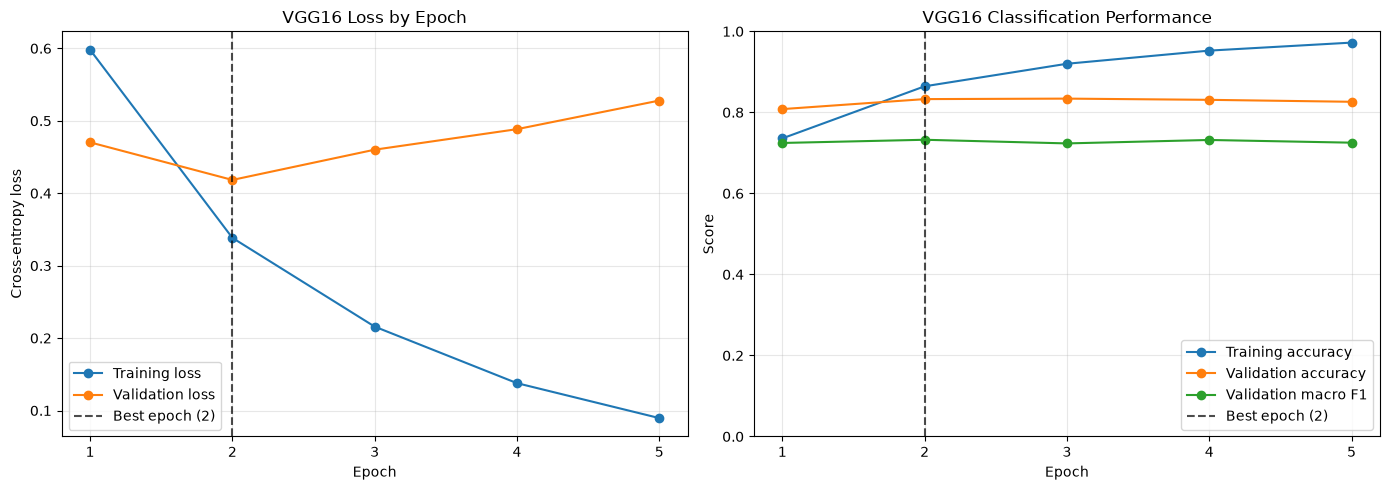

In [31]:
import matplotlib.pyplot as plt


epochs = range(
    1,
    len(history["train_loss"]) + 1,
)

figure, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

# -------------------------
# Loss curve
# -------------------------
axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training loss",
)

axes[0].plot(
    epochs,
    history["validation_loss"],
    marker="o",
    label="Validation loss",
)

axes[0].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    alpha=0.7,
    label=f"Best epoch ({best_epoch})",
)

axes[0].set_title("VGG16 Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_xticks(list(epochs))
axes[0].grid(alpha=0.3)
axes[0].legend()


# -------------------------
# Accuracy and macro F1
# -------------------------
axes[1].plot(
    epochs,
    history["train_accuracy"],
    marker="o",
    label="Training accuracy",
)

axes[1].plot(
    epochs,
    history["validation_accuracy"],
    marker="o",
    label="Validation accuracy",
)

axes[1].plot(
    epochs,
    history["validation_macro_f1"],
    marker="o",
    label="Validation macro F1",
)

axes[1].axvline(
    best_epoch,
    color="black",
    linestyle="--",
    alpha=0.7,
    label=f"Best epoch ({best_epoch})",
)

axes[1].set_title("VGG16 Classification Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks(list(epochs))
axes[1].set_ylim(0.0, 1.0)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## Evaluate the Best Model on Test Set

In [32]:
(
    test_loss,
    test_accuracy,
    test_labels,
    test_predictions,
) = evaluate_model(
    model,
    test_loader,
    criterion,
    device,
)

(
    test_confusion_matrix,
    test_precision,
    test_recall,
    test_f1_scores,
    test_macro_f1,
) = calculate_classification_metrics(
    test_labels,
    test_predictions,
    NUM_CLASSES,
)

print("Final test results:")
print(f"Loss:     {test_loss:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")

print("\nPer-class test results:")

for class_index, class_name in enumerate(CLASS_NAMES):

    class_support = (
        test_labels == class_index
    ).sum().item()

    print(
        f"{class_name:>5} | "
        f"Precision: {test_precision[class_index]:.4f} | "
        f"Recall: {test_recall[class_index]:.4f} | "
        f"F1: {test_f1_scores[class_index]:.4f} | "
        f"Images: {class_support}"
    )

print("\nTest confusion matrix:")
print(test_confusion_matrix)

Evaluating:   0%|          | 0/105 [00:00<?, ?it/s]

Final test results:
Loss:     0.4192
Accuracy: 0.8344
Macro F1: 0.7236

Per-class test results:
angry | Precision: 0.7725 | Recall: 0.7408 | F1: 0.7563 | Images: 463
happy | Precision: 0.9115 | Recall: 0.9407 | F1: 0.9259 | Images: 1029
  sad | Precision: 0.5090 | Recall: 0.4696 | F1: 0.4885 | Images: 181

Test confusion matrix:
tensor([[343,  60,  60],
        [ 39, 968,  22],
        [ 62,  34,  85]])


## Good Looking Results, Now Viualize

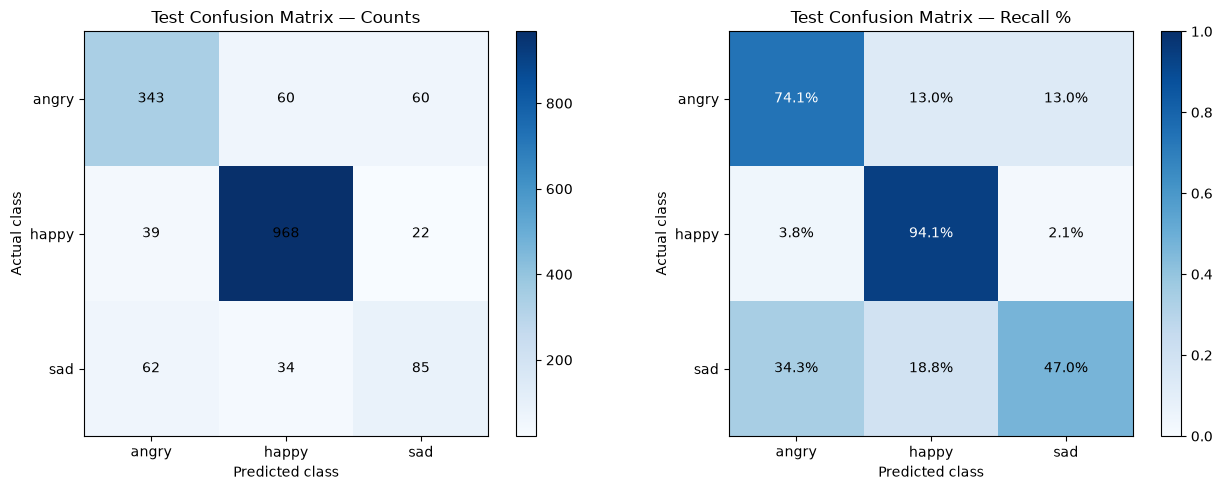

In [33]:
import numpy as np
import matplotlib.pyplot as plt


confusion_counts = (
    test_confusion_matrix
    .cpu()
    .numpy()
)

# Normalize every row by the number of actual images
# belonging to that class.
confusion_percentages = (
    confusion_counts
    / confusion_counts.sum(
        axis=1,
        keepdims=True,
    )
)


figure, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)


# -------------------------
# Raw image counts
# -------------------------
count_image = axes[0].imshow(
    confusion_counts,
    cmap="Blues",
)

axes[0].set_title("Test Confusion Matrix — Counts")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")

axes[0].set_xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
)

axes[0].set_yticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
)

for actual_index in range(NUM_CLASSES):
    for predicted_index in range(NUM_CLASSES):

        axes[0].text(
            predicted_index,
            actual_index,
            confusion_counts[
                actual_index,
                predicted_index,
            ],
            ha="center",
            va="center",
            color="black",
        )

figure.colorbar(
    count_image,
    ax=axes[0],
    fraction=0.046,
)


# -------------------------
# Row-normalized percentages
# -------------------------
percentage_image = axes[1].imshow(
    confusion_percentages,
    cmap="Blues",
    vmin=0,
    vmax=1,
)

axes[1].set_title("Test Confusion Matrix — Recall %")
axes[1].set_xlabel("Predicted class")
axes[1].set_ylabel("Actual class")

axes[1].set_xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
)

axes[1].set_yticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
)

for actual_index in range(NUM_CLASSES):
    for predicted_index in range(NUM_CLASSES):

        value = confusion_percentages[
            actual_index,
            predicted_index,
        ]

        text_color = (
            "white"
            if value > 0.5
            else "black"
        )

        axes[1].text(
            predicted_index,
            actual_index,
            f"{value:.1%}",
            ha="center",
            va="center",
            color=text_color,
        )

figure.colorbar(
    percentage_image,
    ax=axes[1],
    fraction=0.046,
)

plt.tight_layout()
plt.show()

In [34]:
# Add final test results to the checkpoint metadata.
checkpoint["test_results"] = {
    "loss": test_loss,
    "accuracy": test_accuracy,
    "macro_f1": test_macro_f1,

    "per_class_precision": {
        class_name: test_precision[index].item()
        for index, class_name
        in enumerate(CLASS_NAMES)
    },

    "per_class_recall": {
        class_name: test_recall[index].item()
        for index, class_name
        in enumerate(CLASS_NAMES)
    },

    "per_class_f1": {
        class_name: test_f1_scores[index].item()
        for index, class_name
        in enumerate(CLASS_NAMES)
    },

    "confusion_matrix": (
        test_confusion_matrix.tolist()
    ),
}

# Update the existing checkpoint file.
torch.save(
    checkpoint,
    checkpoint_path,
)


# Save the confusion-matrix figure separately.
confusion_matrix_path = (
    checkpoint_directory
    / "vgg16_transfer_v1_confusion_matrix.png"
)

figure.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight",
)


print("Checkpoint updated with test results.")
print("Checkpoint:", checkpoint_path)
print("Confusion matrix:", confusion_matrix_path)
print(
    "Final test accuracy:",
    f"{test_accuracy:.2%}",
)
print(
    "Final test macro F1:",
    f"{test_macro_f1:.2%}",
)

Checkpoint updated with test results.
Checkpoint: C:\Users\mashe\code\class\Capstone-DATA4381\Model_Revisions\vgg16_transfer_v1_best.pt
Confusion matrix: C:\Users\mashe\code\class\Capstone-DATA4381\Model_Revisions\vgg16_transfer_v1_confusion_matrix.png
Final test accuracy: 83.44%
Final test macro F1: 72.36%


In [35]:
# Load the saved checkpoint onto the CPU first.
loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

# Recreate the same VGG16 architecture.
reloaded_model = vgg16(
    weights=None,
)

reloaded_model.classifier = nn.Sequential(
    nn.Linear(
        512 * 7 * 7,
        loaded_checkpoint[
            "classifier_hidden_features"
        ],
    ),
    nn.ReLU(),
    nn.Dropout(
        p=loaded_checkpoint["dropout"],
    ),
    nn.Linear(
        loaded_checkpoint[
            "classifier_hidden_features"
        ],
        loaded_checkpoint["num_classes"],
    ),
)

# Load our trained parameters.
load_result = reloaded_model.load_state_dict(
    loaded_checkpoint["model_state_dict"],
)

reloaded_model = reloaded_model.to(device)
reloaded_model.eval()

# Obtain one test batch for verification.
verification_images, verification_labels = next(
    iter(test_loader)
)

verification_images = verification_images.to(
    device,
    non_blocking=use_pinned_memory,
)

# Compare the current model with the model loaded from disk.
model.eval()

with torch.inference_mode():

    original_logits = model(
        verification_images
    )

    reloaded_logits = reloaded_model(
        verification_images
    )

maximum_difference = (
    original_logits - reloaded_logits
).abs().max().item()

reloaded_predictions = (
    reloaded_logits
    .argmax(dim=1)
    .cpu()
)

print("Checkpoint reload successful.")
print("Missing parameters:", load_result.missing_keys)
print("Unexpected parameters:", load_result.unexpected_keys)
print(
    "Maximum output difference:",
    maximum_difference,
)

print(
    "Actual labels:   ",
    verification_labels[:8].tolist(),
)

print(
    "Reloaded model:  ",
    reloaded_predictions[:8].tolist(),
)

print(
    "Predicted classes:",
    [
        loaded_checkpoint["class_names"][label]
        for label
        in reloaded_predictions[:8].tolist()
    ],
)

Checkpoint reload successful.
Missing parameters: []
Unexpected parameters: []
Maximum output difference: 0.0
Actual labels:    [0, 0, 0, 0, 0, 0, 0, 0]
Reloaded model:   [0, 2, 0, 0, 0, 0, 0, 2]
Predicted classes: ['angry', 'sad', 'angry', 'angry', 'angry', 'angry', 'angry', 'sad']


## Final Results

We implemented a transfer-learning emotion classifier using VGG16 pretrained
on ImageNet. The convolutional feature extractor was frozen, and the original
classifier was replaced with a custom three-class classifier for angry, happy,
and sad facial expressions.

### Training configuration

- Dataset: `aug_data_v1`
- Training images: 14,019
- Validation images: 1,662
- Test images: 1,673
- Input shape: 3 × 224 × 224
- Batch size: 16
- Optimizer: AdamW
- Learning rate: 0.0001
- Weight decay: 0.0001
- Loss function: cross-entropy
- Model-selection metric: validation macro F1

### Final performance

- Best epoch: 2
- Validation macro F1: 73.24%
- Test accuracy: 83.44%
- Test macro F1: 72.36%

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| Angry | 77.25% | 74.08% | 75.63% |
| Happy | 91.15% | 94.07% | 92.59% |
| Sad | 50.90% | 46.96% | 48.85% |

### Interpretation

The model generalized consistently between the validation and test sets.
Happy expressions were classified most reliably. Sad expressions were the
most difficult class and were commonly confused with angry expressions.

Training beyond epoch 2 caused overfitting: training accuracy continued to
increase while validation loss increased and validation macro F1 stopped
improving.

### Future work

- Fine-tune the final VGG16 convolutional block using a smaller learning rate.
- Investigate angry–sad misclassifications.
- Experiment with stronger regularization and targeted augmentation.
- Compare VGG16 against the fully connected and CNN baselines.